## Test WorkFlow

#### By: Josh Navarro

#### Goal: 
Create a decent workflow to describe how we can get the protein prediction working.


#### ====================================================

In [2]:
# Imports that we are going to be using

import pandas as pd
import numpy as np
import cellrank as cr
import scvelo as scv
import matplotlib.pyplot as plt
import anndata as ad
import scanpy as sc
from cellrank.kernels import VelocityKernel, ConnectivityKernel
from cellrank.kernels.utils import RandomWalk


#### Acquire CITE-seq data 
We need to acquire this for the measured protein comparision,

CITE-seq data contains two pieces of infoiramtion the RNA Gene Expression(spliced & unspliced), then the protein abundance, typically from the cell-surface proteins.

Stored as MuData, but we need AnnData?
MuData is the multiple related data types, such as holding many AnnData Objects, typically one anndata that holds the RNA modality, and then seperately the Protein modality.


#### Data that we are using

We are using the data given from Rebecca for now, until we find better suited data. Trying to get the work flow down.

In [2]:
# Read the data given.

adata = sc.read_h5ad(r"C:\Users\joshu\Desktop\RNA_Velocity_R\scVelo\WorkFlow Test\data\janssens_2025_CellRanger_Velocyto_counts_eLNP.h5ad")
print(adata)

AnnData object with n_obs × n_vars = 21327 × 31353
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sum', 'detected', 'subsets_Mito_sum', 'subsets_Mito_detected', 'subsets_Mito_percent', 'subsets_RBC_sum', 'subsets_RBC_detected', 'subsets_RBC_percent', 'subsets_COVID_sum', 'subsets_COVID_detected', 'subsets_COVID_percent', 'total', 'sizeFactor', 'nCount_RNA.y', 'nFeature_RNA.y', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'SCT_snn_res.0', 'SCT_snn_res.0.1', 'SCT_snn_res.0.2', 'SCT_snn_res.0.3', 'SCT_snn_res.0.4', 'SCT_snn_res.0.5', 'SCT_snn_res.0.6', 'SCT_snn_res.0.7', 'SCT_snn_res.0.9', 'SCT_snn_res.1', 'SCT_clusters', 'fzero', 'pca.drop', 'pANN_0.25_0.13_181', 'DFPrediction', 'nCount_ADT', 'nFeature_ADT', 'ADT_snn_res.0.8', 'ADT_snn_res.0', 'ADT_snn_res.0.1', 'ADT_snn_res.0.2', 'ADT_snn_res.0.3', 'ADT_snn_res.0.4', 'ADT_snn_res.0.5', 'ADT_snn_res.0.6', 'ADT_snn_res.0.7', 'ADT_snn_res.0.9', 'ADT_snn_res.1', 'ADT_clusters', 'nCount_HTO', 'nFeature_HTO', 'HT

#### ====================================================

#### Check the spliced and unspliced RNA layers in adata
Check for the spliced and unspliced RNA observations as we need this for the RNA velocity

Need both of the splcied and unspliced since we need to see whether the gene is being actiavated or being reduced.

There is a chance that the CITE-Seq data might not have the RNA data needed, we need to get the raw data and process it using velocyto, to have those layers, then match it with citeseq protien for later comparison, or just find a data set that either has the velocity already a layer, or have the spliced or unspliced.

In [3]:
# Check for the the layers spliced and unspliced
print("spliced" in adata.layers.keys())
print("unspliced" in adata.layers.keys())

True
True


#### ====================================================

#### scVelo Preprocessing
Use the tools in scVELO for preprocessing such as filtering out genes that have very little to none spliced/unspliced info, normalization to have cells that have differing RNA counts a better chance. 

Calculate the neighborhood smoothed spliced and unspliced measurements. To create a more stable stiemate of the local RNA state using the measurements of nearby cells.

In [4]:
# Preprocess the data

scv.pp.filter_and_normalize(
    adata,
    min_shared_counts=20,
)

scv.pp.moments(
    adata, 
    n_pcs = 30,
    n_neighbors = 30 
)

sc.tl.umap(adata)

Filtered out 23855 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.


C:\Users\joshu\AppData\Local\Temp\ipykernel_18452\3620609724.py:8: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scv.pp.moments(
c:\Users\joshu\miniconda3\envs\scvelo_env\Lib\site-packages\scvelo\preprocessing\moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
c:\Users\joshu\miniconda3\envs\scvelo_env\Lib\site-packages\scvelo\preprocessing\neighbors.py:233: DeprecationWarning: Automatic computation of PCA is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute PCA with Scanpy first.
  _set_pca(adata=adata, n_pcs=n_pcs, use_highly_variable=use_highly_variable)


computing neighbors
    finished (0:01:44) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:40) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


#### ====================================================

#### scVelo recover dynamics
Use this function to recover the full splicing kinetics of the selected genes. 

Attemps to create this dynamuical curve that can explain how the gene will move through the induction and repression

In [ ]:
# Try to use n_top_genes to make this process quicker

In [5]:
# Recover the splicing kinetics of the genes

scv.tl.recover_dynamics(adata, n_jobs = 4, n_top_genes = 2000)

recovering dynamics (using 4/8 cores)
or disable the progress bar using `show_progress_bar=False`.
    finished (0:37:29) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)


#### ====================================================

#### scVelo dynamical RNA velocity
Create the RNA velocity using the preroccessed adata and the dyanmaics that were created with recover dynamics

Will predict whether the amount of mature splcied RNA willbe increaseing or decreasing we are able to geta  asense of direction based on that ratio

From this each cell will get a velocity vecotr for each gene with the value that shows positive or negative velocity.

In [6]:
# Find the dynamical RNA Velocity

scv.tl.velocity(
    adata,
    mode = "dynamical"
)

computing velocities
    finished (0:01:01) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)


In [7]:
# Build the velocity graph

scv.tl.velocity_graph(adata)

computing velocity graph (using 1/8 cores)
    finished (0:04:16) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


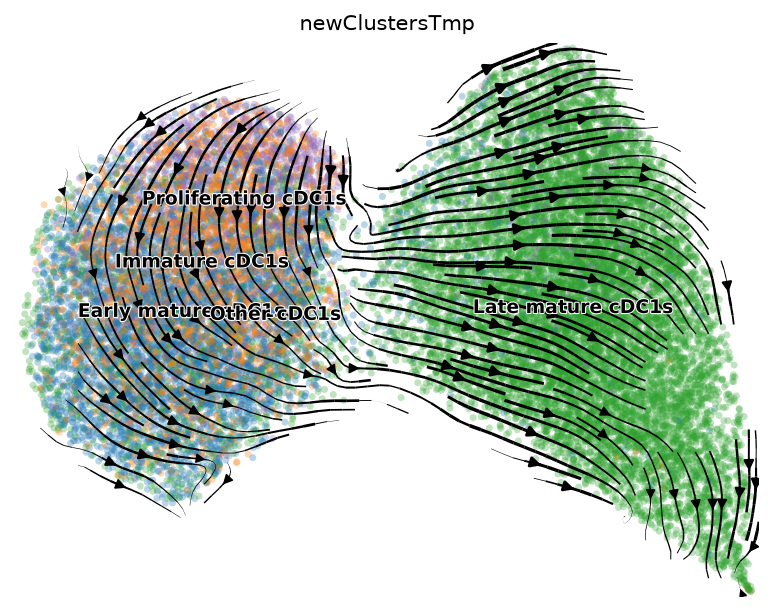

In [18]:
scv.pl.velocity_embedding_stream(
    adata,
    basis="umap",
    color="newClustersTmp",
    legend_fontsize=9,
    dpi=150            # increase dpi for higher resolution
)

#### ====================================================

#### CellRank Velocity kernel 
CellRANK is able to take the single cell information and then create a cell-to-cell transition matrix.

Specifically the Velocity Kernel is made specifically to handle the RNA velocity. For each cell it considers the cell RNA-vel direction, the positions of its nearby neighbors, and the neighboring cells that are in the same direction of the velocity.

In [3]:
# Create the cell rank velocity kernel

adata = sc.read_h5ad(r"C:\Users\joshu\Desktop\RNA_Velocity_R\scVelo\WorkFlow Test\data\dynamic_data.h5ad")
vk = cr.kernels.VelocityKernel(adata)

In [7]:
adata

AnnData object with n_obs × n_vars = 21327 × 7498
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sum', 'detected', 'subsets_Mito_sum', 'subsets_Mito_detected', 'subsets_Mito_percent', 'subsets_RBC_sum', 'subsets_RBC_detected', 'subsets_RBC_percent', 'subsets_COVID_sum', 'subsets_COVID_detected', 'subsets_COVID_percent', 'total', 'sizeFactor', 'nCount_RNA.y', 'nFeature_RNA.y', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'SCT_snn_res.0', 'SCT_snn_res.0.1', 'SCT_snn_res.0.2', 'SCT_snn_res.0.3', 'SCT_snn_res.0.4', 'SCT_snn_res.0.5', 'SCT_snn_res.0.6', 'SCT_snn_res.0.7', 'SCT_snn_res.0.9', 'SCT_snn_res.1', 'SCT_clusters', 'fzero', 'pca.drop', 'pANN_0.25_0.13_181', 'DFPrediction', 'nCount_ADT', 'nFeature_ADT', 'ADT_snn_res.0.8', 'ADT_snn_res.0', 'ADT_snn_res.0.1', 'ADT_snn_res.0.2', 'ADT_snn_res.0.3', 'ADT_snn_res.0.4', 'ADT_snn_res.0.5', 'ADT_snn_res.0.6', 'ADT_snn_res.0.7', 'ADT_snn_res.0.9', 'ADT_snn_res.1', 'ADT_clusters', 'nCount_HTO', 'nFeature_HTO', 'HTO

#### ====================================================

#### Cell-to-cell Transition Matrix
This is the matrix that that has for each row and column a cell, and then the values inside the matrix will be the probability of the cell transitioning.

Wiht this you are able to identify the downstream cells, which you can identify the proteins in the downstream cells.

In [4]:
# Compute the transition matrix
vk.compute_transition_matrix(model = 'deterministic')
ck = cr.kernels.ConnectivityKernel(adata)
ck.compute_transition_matrix()
combined_kernel = 0.8 * vk + 0.2 * ck
trans_matrix = combined_kernel.transition_matrix
# Check the shape of the matrix
trans_matrix.shape

100%|██████████| 21327/21327 [00:25<00:00, 825.18cell/s] 


(21327, 21327)

In [11]:
print(trans_matrix)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 927966 stored elements and shape (21327, 21327)>
  Coords	Values
  (0, 20396)	0.029974205025365897
  (0, 16072)	0.011691938399490261
  (0, 11710)	0.011398266410207135
  (0, 9043)	0.06398677140943873
  (0, 8922)	0.005280805674553554
  (0, 8617)	0.07730282633121206
  (0, 8480)	0.02964132583447102
  (0, 8162)	0.05148353758186179
  (0, 8064)	0.010620550530741344
  (0, 7887)	0.029352745114027055
  (0, 7537)	0.008913140526048637
  (0, 7536)	0.021362451447564393
  (0, 7135)	0.01868965165416672
  (0, 7077)	0.015726275847201238
  (0, 7035)	0.005222517730597675
  (0, 6793)	0.02478858029692847
  (0, 6313)	0.028601735837847735
  (0, 6302)	0.007141592910803032
  (0, 6137)	0.026414822859050273
  (0, 6003)	0.04369260723760375
  (0, 5620)	0.057867957305882727
  (0, 5375)	0.005658840043247576
  (0, 5190)	0.0029421229083601884
  (0, 3995)	0.07158733693922138
  (0, 3902)	0.04017037869225067
  :	:
  (21326, 12684)	0.02810811734121389
  (21326, 

In [ ]:
# 1. Initialize the estimator with your computed kernel
g = cr.estimators.GPCCA(trans_matrix)

# 2. Compute macrostates (groups of cells with similar dynamics)
g.compute_macrostates(n_states=5, cluster_key="newClustersTmp")

# 3. Plot the transition probabilities among macrostates as a clean matrix heatmap
g.plot_macrostate_transitions()

KeyError: "Unable to find clusters in `adata.obs['newClustersTmp']`."

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract the raw transition matrix array
# (It's a scipy sparse matrix, so we convert a subset to dense)
raw_matrix = vk.transition_matrix[0:100, 0:100].toarray()

# 2. Plot as a standard heatmap matrix
plt.figure(figsize=(8, 6))
sns.heatmap(vk, cmap="viridis", vmax=0.1)  # vmax adjusts contrast for sparse values
plt.title("Cell-by-Cell Transition Matrix Subset")
plt.xlabel("Target Cells")
plt.ylabel("Source Cells")
plt.show()

ValueError: setting an array element with a sequence. The requested array would exceed the maximum number of dimension of 32.

<Figure size 800x600 with 0 Axes>

In [13]:
adata.write('dynamic_data.h5ad')

#### ====================================================

#### Create the Random Walks
We use the cell rank random walks multiple times to simulate the possible path that cell couldve taken using the transition matrix that was used previously.

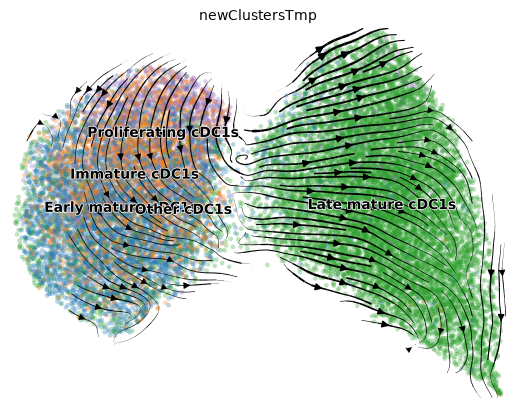

In [15]:
# Create the RNA velocity map

vk.plot_projection(color = "newClustersTmp")

Interesting compared to the velovi the graph looks a lot smoother, and more of what I think what we are looking for

In [35]:
adata.obsp.keys()

KeysView(PairwiseArrays with keys: distances, connectivities)

In [37]:
for col in adata.obs.columns:
    values = adata.obs[col].astype(str).unique()

    if len(values) <= 10:
        print(col, values)

orig.ident ['VBO009' 'VBO005']
subsets_RBC_sum ['0']
subsets_RBC_detected ['0']
subsets_RBC_percent ['0']
subsets_COVID_sum ['0']
subsets_COVID_detected ['0']
subsets_COVID_percent ['0']
seurat_clusters ['1' '0' '6' '2' '3' '4' '5' '7']
SCT_snn_res.0 ['0']
SCT_snn_res.0.1 ['0' '1' '3' '2']
SCT_snn_res.0.2 ['2' '0' '1' '5' '4' '3' '7']
SCT_snn_res.0.3 ['3' '0' '1' '2' '6' '5' '4' '8']
SCT_snn_res.0.4 ['3' '0' '1' '5' '2' '7' '6' '4' '9' '8']
pca.drop ['False' 'True']
pANN_0.25_0.13_181 ['nan']
DFPrediction ['Low Confidence' 'Singlet']
ADT_snn_res.0 ['0']
ADT_snn_res.0.1 ['0' '1']
ADT_snn_res.0.2 ['0' '2' '1']
ADT_snn_res.0.3 ['2' '1' '0' '4' '3']
ADT_snn_res.0.4 ['0' '1' '2' '5' '4' '3' '6']
ADT_snn_res.0.5 ['0' '1' '7' '4' '5' '6' '2' '3']
ADT_snn_res.0.6 ['0' '3' '7' '9' '2' '4' '5' '1' '8' '6']
ADT_snn_res.0.7 ['3' '2' '0' '1' '7' '6' '5' '4' '8']
nFeature_HTO ['3' '2' '1' '4']
HTO_maxID ['Hashtag4' 'Hashtag2' 'Hashtag3' 'Hashtag1']
HTO_secondID ['Hashtag2' 'Hashtag4' 'Hashtag1' 'Has

In [ ]:
# Visualize it
t_mat = trans_matrix
start_cell = adata.obs_names[5000]

In [43]:
# Create the randome walks
rw  = RandomWalk(
    transition_matrix=t_mat, 
    adata = adata, 
    start_ixs = [start_cell]
)
sims = rw.simulate_many(
    n_sims=100, 
    max_iter=100, 
    seed=0, 
    successive_hits=0
)
walks_arr = np.stack(sims)

emb = adata.obsm["X_umap"]
coords = emb[walks_arr] 
avg_trajectory = coords.mean(axis=0)

100%|██████████| 100/100 [00:01<00:00, 54.20sim/s]


#### ====================================================

#### Visualize the Random Walks

We use the matplotlib to visualize the path that the cell took from the previous ran random walks

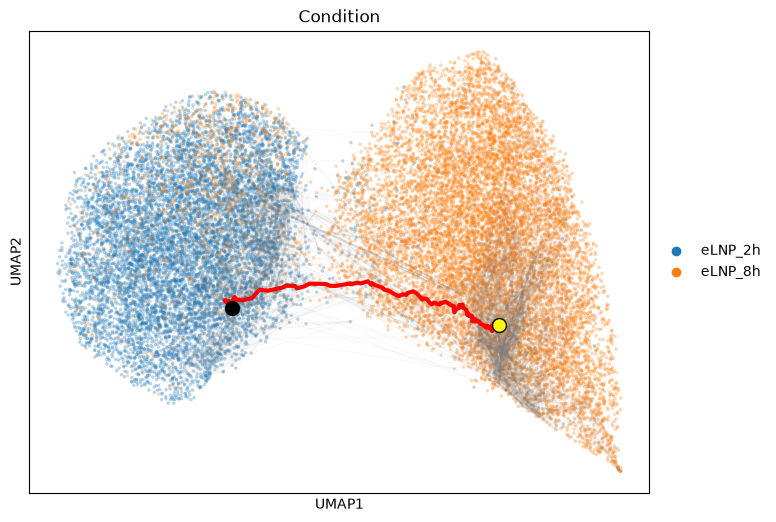

In [44]:
fig, ax = plt.subplots(figsize=(8, 6))
sc.pl.embedding(
    adata, 
    basis="umap", 
    color="Condition", 
    ax=ax, 
    show=False, 
    alpha=0.3, 
    size=25
)

# plot faint lines for individual walks
for i in range(coords.shape[0]):
    ax.plot(
        coords[i, :, 0], 
        coords[i, :, 1], 
        color="gray", 
        alpha=0.05, 
        linewidth=0.8, 
        zorder=4
    )

# average, bold
ax.plot(
    avg_trajectory[:, 0], 
    avg_trajectory[:, 1], 
    color="red", 
    linewidth=3, 
    zorder=5
)
ax.scatter(
    *avg_trajectory[0], 
    color="black", 
    s=100, 
    zorder=6
)
ax.scatter(
    *avg_trajectory[-1], 
    color="yellow", 
    edgecolor="black", 
    s=100, 
    zorder=6
)

plt.show()

This looks drastically different then what rebecca got. I think this is because of t_fwd I dont knwo what that is.

In [45]:
scv.tl.latent_time(adata)

computing latent time using root_cells as prior
    finished (0:00:18) --> added 
    'latent_time', shared time (adata.obs)


In [46]:
latent_time = adata.obs["latent_time"]
adata.obs['avg_latent_time'] = latent_time

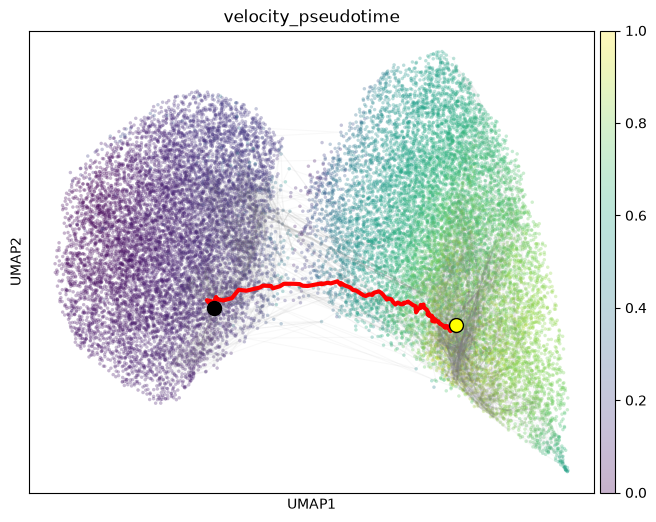

In [47]:
fig, ax = plt.subplots(figsize=(8, 6))
sc.pl.embedding(
    adata, 
    basis="umap", 
    color="velocity_pseudotime", 
    ax=ax, show=False, 
    alpha=0.3, 
    size=25
)

# plot faint lines for individual walks
for i in range(coords.shape[0]):
    ax.plot(
        coords[i, :, 0], 
        coords[i, :, 1], 
        color="gray", 
        alpha=0.05, 
        linewidth=0.8, 
        zorder=4
    )

# average, bold
ax.plot(
    avg_trajectory[:, 0], 
    avg_trajectory[:, 1], 
    color="red", 
    linewidth=3, 
    zorder=5
)
ax.scatter(
    *avg_trajectory[0], 
    color="black", 
    s=100, 
    zorder=6
)
ax.scatter(
    *avg_trajectory[-1], 
    color="yellow", 
    edgecolor="black", 
    s=100, 
    zorder=6
)

plt.show()

#### ====================================================

#### Comparing the latent time to the average walk step

We use matplotlib to visualize the walk step compared to the latent time, to see if the data is matching. Whether the walk step is heading toward a later stage being the latent time.

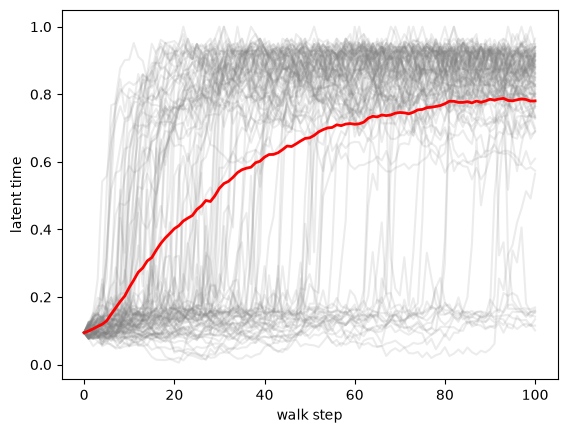

In [48]:
lt = adata.obs["velocity_pseudotime"].values   # numpy array, aligned with adata's row order
walk_latent_times = lt[walks_arr] 

for i in range(walk_latent_times.shape[0]):
    plt.plot(walk_latent_times[i], color="gray", alpha=0.15)

plt.plot(np.nanmean(walk_latent_times, axis=0), color="red", linewidth=2)
plt.xlabel("walk step")
plt.ylabel("latent time")
plt.show()

#### ====================================================

#### Connect the transition Matrix to the measured CITE-seq Proteins.

